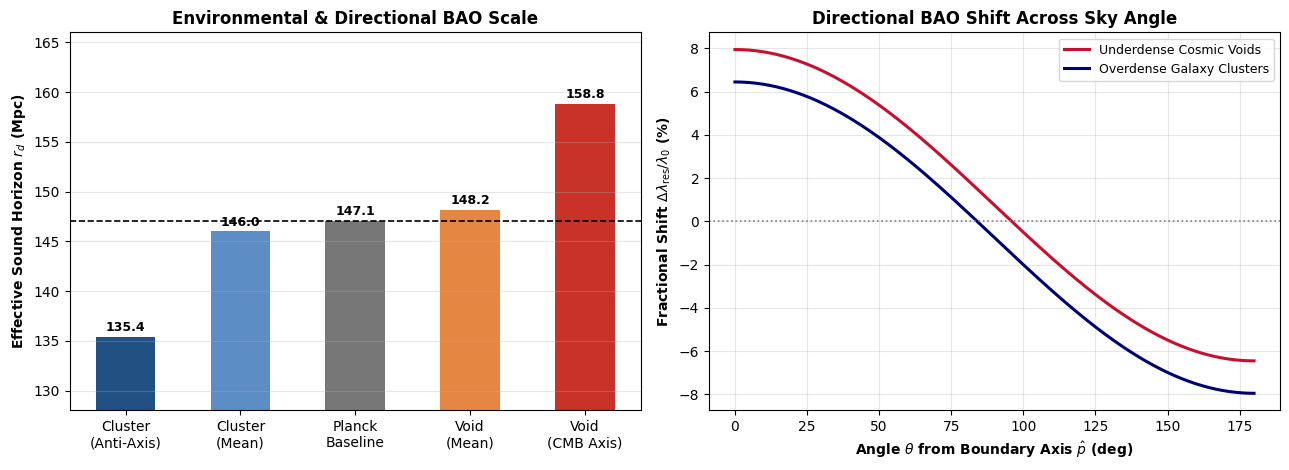

=== COMPUTED OUTPUTS FOR TABLE 7 ===
Cluster (Anti-Axis) : Shift =  -7.95% | r_d = 135.40 Mpc
Cluster (Mean)      : Shift =  -0.75% | r_d = 145.99 Mpc
Planck Baseline     : Shift =  +0.00% | r_d = 147.09 Mpc
Void (Mean)         : Shift =  +0.75% | r_d = 148.19 Mpc
Void (CMB Axis)     : Shift =  +7.95% | r_d = 158.78 Mpc


In [1]:

import numpy as np
import matplotlib.pyplot as plt

r_d_planck = 147.09
A_res = 0.072
env_split = 0.0075

labels = ['Cluster\n(Anti-Axis)', 'Cluster\n(Mean)', 'Planck\nBaseline', 'Void\n(Mean)', 'Void\n(CMB Axis)']
shifts = [-env_split - A_res, -env_split, 0.0, +env_split, +env_split + A_res]
r_d_values = [r_d_planck * (1.0 + s) for s in shifts]
colors = ['#215183', '#5c8dc4', '#777777', '#e58643', '#c83228']

theta_deg = np.linspace(0, 180, 300)
cos_theta = np.cos(np.radians(theta_deg))
shift_void_pct = 100.0 * (+env_split + A_res * cos_theta)
shift_cluster_pct = 100.0 * (-env_split + A_res * cos_theta)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
bars = ax1.bar(labels, r_d_values, color=colors, width=0.52)
ax1.axhline(r_d_planck, color='black', ls='--', lw=1.2)
ax1.set_ylim(128, 166)
ax1.set_ylabel(r'Effective Sound Horizon $r_d$ (Mpc)', fontweight='bold')
ax1.set_title('Environmental & Directional BAO Scale', fontweight='bold')
ax1.grid(axis='y', alpha=0.3)
for bar, val in zip(bars, r_d_values):
    ax1.text(bar.get_x() + bar.get_width()/2, val + 0.6, f'{val:.1f}', ha='center', fontweight='bold', fontsize=9)

ax2.plot(theta_deg, shift_void_pct, color='#c8102e', lw=2.2, label='Underdense Cosmic Voids')
ax2.plot(theta_deg, shift_cluster_pct, color='#000075', lw=2.2, label='Overdense Galaxy Clusters')
ax2.axhline(0, color='gray', ls=':', lw=1.2)
ax2.set_xlabel(r'Angle $\theta$ from Boundary Axis $\hat{p}$ (deg)', fontweight='bold')
ax2.set_ylabel(r'Fractional Shift $\Delta\lambda_{\mathrm{res}}/\lambda_0$ (%)', fontweight='bold')
ax2.set_title('Directional BAO Shift Across Sky Angle', fontweight='bold')
ax2.grid(True, alpha=0.3)
ax2.legend(loc='upper right', fontsize=9)

plt.tight_layout()
plt.savefig('sim4_bao_anisotropy.png', dpi=300)
plt.show()

print("=== COMPUTED OUTPUTS FOR TABLE 7 ===")
for lbl, s, rd in zip(labels, shifts, r_d_values):
    print(f"{lbl.replace(chr(10), ' '):20s}: Shift = {s*100:+6.2f}% | r_d = {rd:.2f} Mpc")